<a href="https://colab.research.google.com/github/shahriarshadhin3-alt/uterine-emg-preterm-detection/blob/main/notebooks/02_metadata_and_signal_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 02 - Metadata and Signal Analysis

## Objective
Understand the TPEHG dataset using Python.

## Tasks
1. Read pregnancy metadata.
2. Identify Term and Preterm records.
3. Count the records in each class.
4. Visualize class distribution.
5. Understand the 12 signal columns.
6. Explore basic signal statistics.


In [11]:

!pip install -q wfdb PyWavelets


In [3]:

# Import libraries

import pandas as pd
import numpy as np
import requests
import re

# Download metadata from PhysioNet

metadata_url = (
    "https://physionet.org/files/"
    "tpehgdb/1.0.1/tpehgdb.smr"
)

response = requests.get(metadata_url)
response.raise_for_status()

print("Metadata downloaded successfully!")

# Read metadata text

lines = response.text.splitlines()

# Find the actual table header
header_index = next(
    i for i, line in enumerate(lines)
    if "Record" in line and "Gestation" in line
)

# Extract column names
columns = [
    item.strip()
    for item in lines[header_index].strip().strip("|").split("|")
]

# Extract data rows
rows = []

for line in lines[header_index + 1:]:

    # Skip empty and separator lines
    if not line.strip() or re.fullmatch(r"[\s|+\-]+", line):
        continue

    if "|" not in line:
        continue

    values = [
        item.strip()
        for item in line.strip().strip("|").split("|")
    ]

    if len(values) == len(columns):
        if values[0].startswith("tpehg"):
            rows.append(values)

# Create DataFrame
df = pd.DataFrame(rows, columns=columns)

# Convert numeric columns
df["Gestation"] = pd.to_numeric(df["Gestation"])
df["Rec. time"] = pd.to_numeric(df["Rec. time"])

print("\nMetadata loaded successfully!")
print("Dataset shape:", df.shape)

# Display first five records
df.head()


Metadata downloaded successfully!

Metadata loaded successfully!
Dataset shape: (300, 6)


,Record,Gestation,Rec. time,Group,Premature,Early
0,tpehg1007,35.00,31.29,>=26-PRE,t,f
1,tpehg1021,38.57,22.29,<26-TERM,f,t
2,tpehg1022,38.57,31.00,>=26-TERM,f,f
3,tpehg1027,37.14,31.29,>=26-TERM,f,f
4,tpehg1029,38.57,31.00,>=26-TERM,f,f


In [5]:

# Count Term and Preterm records

print("Original labels:")
print(df["Premature"].value_counts())

# Convert labels into readable names

df["Class"] = df["Premature"].str.lower().map({
    "t": "Preterm",
    "f": "Term"
})

# Count each class

class_counts = df["Class"].value_counts()

print("\nPregnancy Classification:")
print(class_counts)

# Check total records

print("\nTotal records:", len(df))


Original labels:
Premature
f    262
t     38
Name: count, dtype: int64

Pregnancy Classification:
Class
Term       262
Preterm     38
Name: count, dtype: int64

Total records: 300


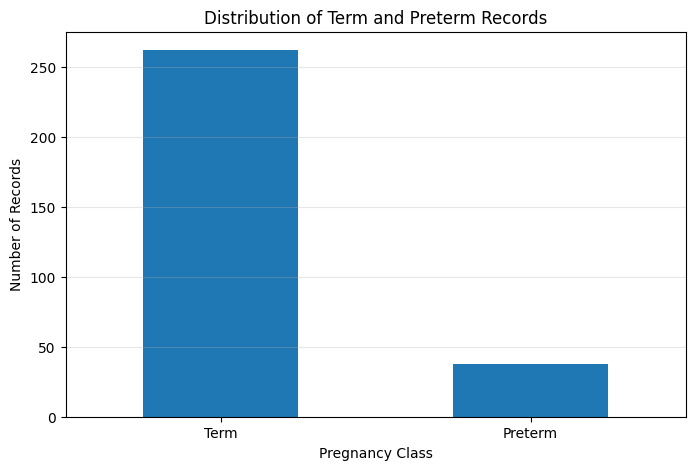

In [7]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

class_counts.plot(
    kind="bar",
    rot=0
)

plt.title("Distribution of Term and Preterm Records")
plt.xlabel("Pregnancy Class")
plt.ylabel("Number of Records")

plt.grid(axis="y", alpha=0.3)
plt.show()


In [8]:

# Calculate percentage of each class

class_percentage = (
    df["Class"].value_counts(normalize=True) * 100
)

print(class_percentage.round(2))


Class
Term       87.33
Preterm    12.67
Name: proportion, dtype: float64


In [12]:

# Load the EHG recording again in this notebook

import wfdb
import numpy as np

record = wfdb.rdrecord(
    "tpehg1007",
    pn_dir="tpehgdb/1.0.1/tpehgdb"
)

print("Recording loaded successfully!")
print("Signal shape:", record.p_signal.shape)
print("Number of channels:", record.n_sig)


Recording loaded successfully!
Signal shape: (35180, 12)
Number of channels: 12


In [13]:

# Explore the 12 signal columns

for i, name in enumerate(record.sig_name):

    physical_channel = ["S1", "S2", "S3"][i // 4]

    versions = [
        "Unfiltered",
        "0.08-4 Hz",
        "0.3-3 Hz",
        "0.3-4 Hz"
    ]

    version = versions[i % 4]

    print(
        "Column:", i,
        "| Channel:", physical_channel,
        "| Version:", version,
        "| Header name:", name
    )


Column: 0 | Channel: S1 | Version: Unfiltered | Header name: 1
Column: 1 | Channel: S1 | Version: 0.08-4 Hz | Header name: 1_DOCFILT-4-0.08-4
Column: 2 | Channel: S1 | Version: 0.3-3 Hz | Header name: 1_DOCFILT-4-0.3-3
Column: 3 | Channel: S1 | Version: 0.3-4 Hz | Header name: 1_DOCFILT-4-0.3-4
Column: 4 | Channel: S2 | Version: Unfiltered | Header name: 2
Column: 5 | Channel: S2 | Version: 0.08-4 Hz | Header name: 2_DOCFILT-4-0.08-4
Column: 6 | Channel: S2 | Version: 0.3-3 Hz | Header name: 2_DOCFILT-4-0.3-3
Column: 7 | Channel: S2 | Version: 0.3-4 Hz | Header name: 2_DOCFILT-4-0.3-4
Column: 8 | Channel: S3 | Version: Unfiltered | Header name: 3
Column: 9 | Channel: S3 | Version: 0.08-4 Hz | Header name: 3_DOCFILT-4-0.08-4
Column: 10 | Channel: S3 | Version: 0.3-3 Hz | Header name: 3_DOCFILT-4-0.3-3
Column: 11 | Channel: S3 | Version: 0.3-4 Hz | Header name: 3_DOCFILT-4-0.3-4


In [14]:

# Select first unfiltered EHG channel

signal = record.p_signal[:, 0]

# Calculate statistical features

mean_value = np.mean(signal)

std_value = np.std(signal)

min_value = np.min(signal)

max_value = np.max(signal)

rms_value = np.sqrt(np.mean(signal**2))

# Display results

print("Mean:", mean_value)

print("Standard Deviation:", std_value)

print("Minimum:", min_value)

print("Maximum:", max_value)

print("RMS:", rms_value)


Mean: -1.613301078589042e-05
Standard Deviation: 0.04884442702979799
Minimum: -0.27832455939574274
Maximum: 0.18989852750438696
RMS: 0.04884442969411453
